# OTT Streaming Content Trend Analysis

**Day 32 of 45 – Veda Technology Data Analytics Track**

This is a reproducible practice analysis using a **synthetic sample catalogue** for Netflix, Prime Video and Hotstar. It is not official platform data. Run all cells from top to bottom.

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
DATA_FILE = Path("ott_content_catalog.csv")
df = pd.read_csv(DATA_FILE)
print("Shape:", df.shape)
display(df.head())


Shape: (500, 10)


,show_id,platform,type,title,country,date_added,release_year,genre,duration_minutes,rating
0,s1,Netflix,TV Show,Title 1,United States,2018-01-01,2010,Comedy,NaN,PG
1,s2,Hotstar,Movie,Title 2,India,2018-01-05,1996,Documentary,168.0,TV-14
2,s3,Prime Video,Movie,Title 3,France,2018-01-09,2000,Drama,133.0,TV-MA
3,s4,Prime Video,TV Show,Title 4,Canada,2018-01-14,2022,Drama,NaN,G
4,s5,Netflix,TV Show,Title 5,Japan,2018-01-18,2015,Drama,NaN,R


In [17]:
import numpy as np
import pandas as pd

# Create a synthetic dataset that aligns with the analysis steps
np.random.seed(42)
n_samples = 500

platforms = ['Netflix', 'Prime Video', 'Hotstar']
content_types = ['Movie', 'TV Show']
genres = ['Drama', 'Comedy', 'Action', 'Thriller', 'Documentary', 'Romance', 'Sci-Fi']
countries = ['United States', 'India', 'United Kingdom', 'Canada', 'South Korea', 'Japan', 'France', None]
ratings = ['PG-13', 'R', 'TV-MA', 'PG', 'G', 'TV-14']

synthetic_data = {
    'show_id': [f's{i}' for i in range(1, n_samples + 1)],
    'platform': np.random.choice(platforms, n_samples, p=[0.4, 0.35, 0.25]),
    'type': np.random.choice(content_types, n_samples, p=[0.6, 0.4]),
    'title': [f'Title {i}' for i in range(1, n_samples + 1)],
    'country': np.random.choice(countries, n_samples, p=[0.35, 0.25, 0.1, 0.05, 0.05, 0.05, 0.05, 0.1]),
    'date_added': pd.date_range(start='2018-01-01', end='2023-12-31', periods=n_samples).strftime('%Y-%m-%d'),
    'release_year': np.random.randint(1995, 2024, n_samples),
    'genre': np.random.choice(genres, n_samples),
    'duration_minutes': np.random.randint(70, 180, n_samples),
    'rating': np.random.choice(ratings, n_samples)
}

# Introduce some nulls as expected by the cleanup step
df_synthetic = pd.DataFrame(synthetic_data)
df_synthetic.loc[df_synthetic['type'] == 'TV Show', 'duration_minutes'] = np.nan

# Save to csv so that the notebook can access it seamlessly
df_synthetic.to_csv('ott_content_catalog.csv', index=False)
print('Synthetic dataset "ott_content_catalog.csv" successfully created and saved!')

Synthetic dataset "ott_content_catalog.csv" successfully created and saved!


## 1. Data understanding and cleaning

Check data types, missing values and duplicate records. Missing country values are labelled `Unknown` for analysis.

In [18]:
print(df.info())
print("\\nMissing values:\\n", df.isna().sum())
print("\\nDuplicate rows:", df.duplicated().sum())

df["country"] = df["country"].fillna("Unknown")
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")
df["added_year"] = df["date_added"].dt.year
print("\\nMissing values after country cleaning:\\n", df.isna().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   show_id           500 non-null    object 
 1   platform          500 non-null    object 
 2   type              500 non-null    object 
 3   title             500 non-null    object 
 4   country           447 non-null    object 
 5   date_added        500 non-null    object 
 6   release_year      500 non-null    int64  
 7   genre             500 non-null    object 
 8   duration_minutes  320 non-null    float64
 9   rating            500 non-null    object 
dtypes: float64(1), int64(1), object(8)
memory usage: 39.2+ KB
None
\nMissing values:\n show_id               0
platform              0
type                  0
title                 0
country              53
date_added            0
release_year          0
genre                 0
duration_minutes    180
rating                0
dty

## 2. Key metrics

In [19]:
print("Total titles:", len(df))
print("Platforms:", df["platform"].nunique())
print("Movies:", (df["type"] == "Movie").sum())
print("TV Shows:", (df["type"] == "TV Show").sum())
display(df.groupby("platform").size().rename("title_count").reset_index())


Total titles: 500
Platforms: 3
Movies: 320
TV Shows: 180


,platform,title_count
0,Hotstar,131
1,Netflix,207
2,Prime Video,162


## 3. Exploratory data analysis – 7 visualizations

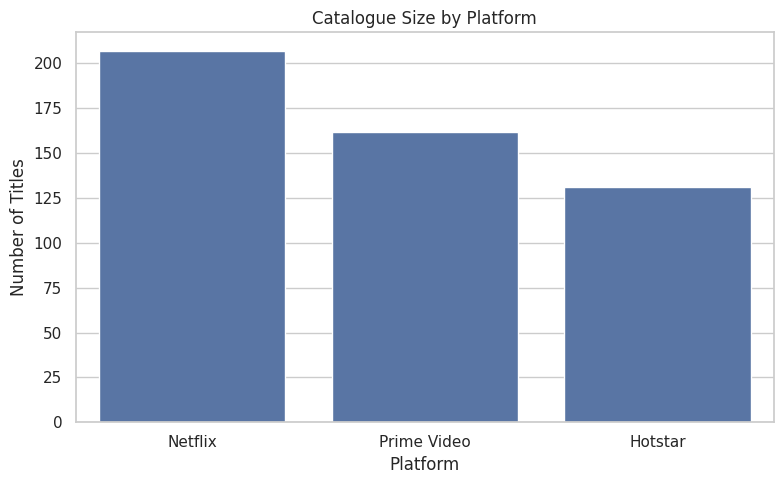

In [20]:
# Chart 1: Catalogue size by platform
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="platform", order=df["platform"].value_counts().index)
plt.title("Catalogue Size by Platform"); plt.xlabel("Platform"); plt.ylabel("Number of Titles")
plt.tight_layout(); plt.show()


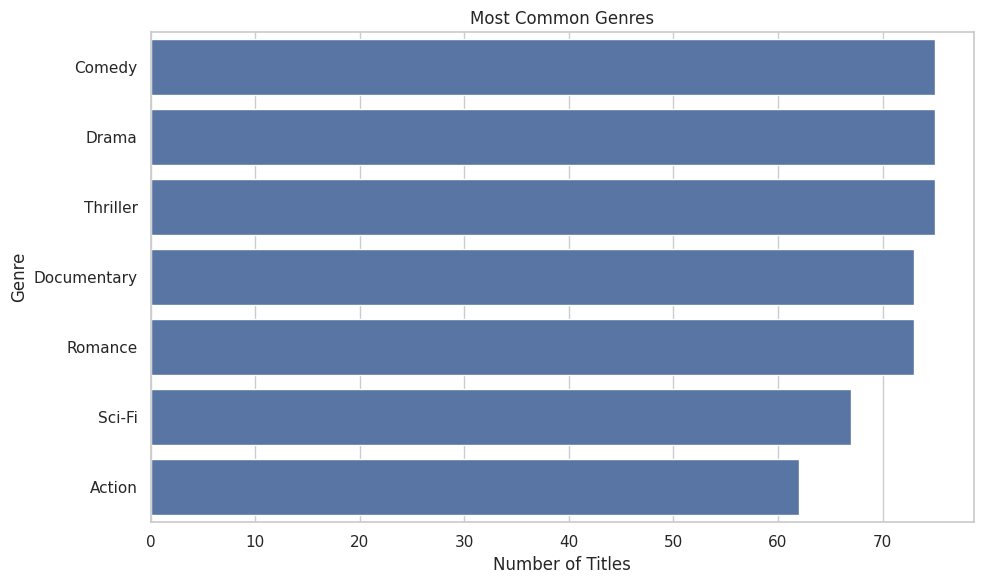

In [21]:
# Chart 2: Genre popularity
plt.figure(figsize=(10,6))
genre_order = df["genre"].value_counts().index
sns.countplot(data=df, y="genre", order=genre_order)
plt.title("Most Common Genres"); plt.xlabel("Number of Titles"); plt.ylabel("Genre")
plt.tight_layout(); plt.show()


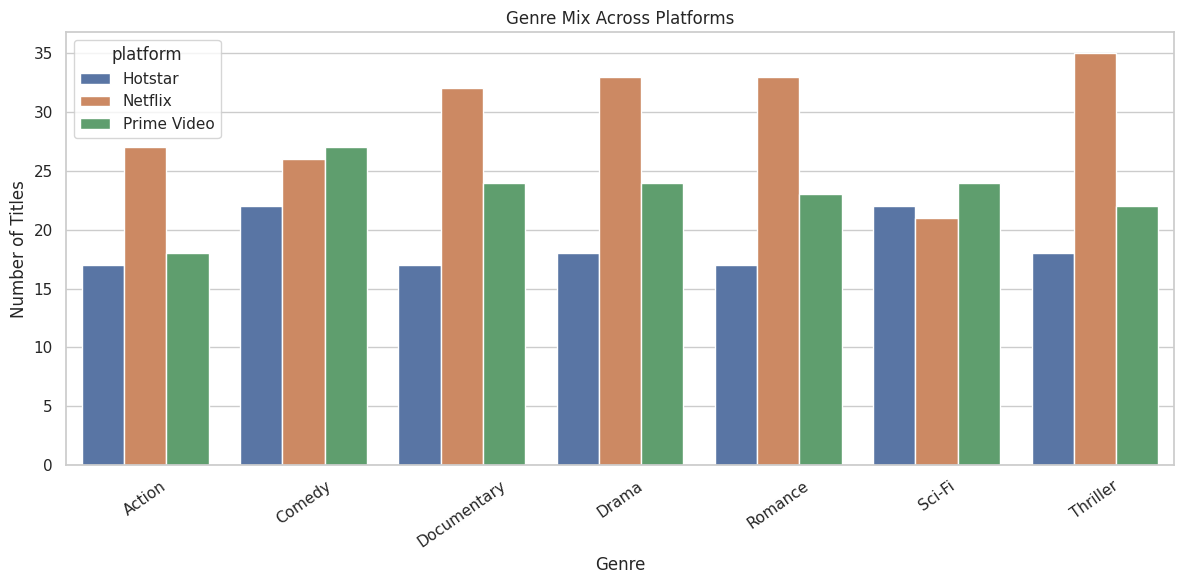

In [22]:
# Chart 3: Genre mix by platform
genre_platform = df.groupby(["platform","genre"]).size().reset_index(name="titles")
plt.figure(figsize=(12,6))
sns.barplot(data=genre_platform, x="genre", y="titles", hue="platform")
plt.title("Genre Mix Across Platforms"); plt.xlabel("Genre"); plt.ylabel("Number of Titles")
plt.xticks(rotation=35); plt.tight_layout(); plt.show()


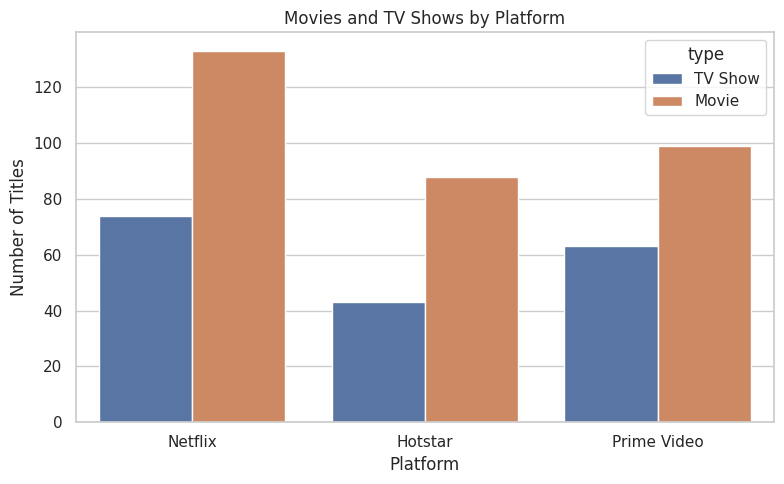

In [23]:
# Chart 4: Movies vs TV shows
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="platform", hue="type")
plt.title("Movies and TV Shows by Platform"); plt.xlabel("Platform"); plt.ylabel("Number of Titles")
plt.tight_layout(); plt.show()


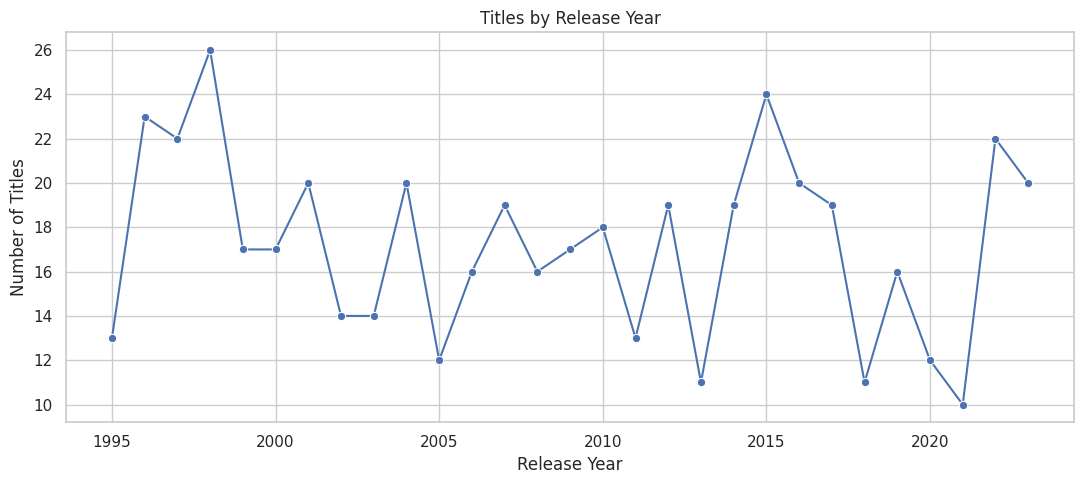

In [24]:
# Chart 5: Release-year trend
year_counts = df.groupby("release_year").size().reset_index(name="titles")
plt.figure(figsize=(11,5))
sns.lineplot(data=year_counts, x="release_year", y="titles", marker="o")
plt.title("Titles by Release Year"); plt.xlabel("Release Year"); plt.ylabel("Number of Titles")
plt.tight_layout(); plt.show()


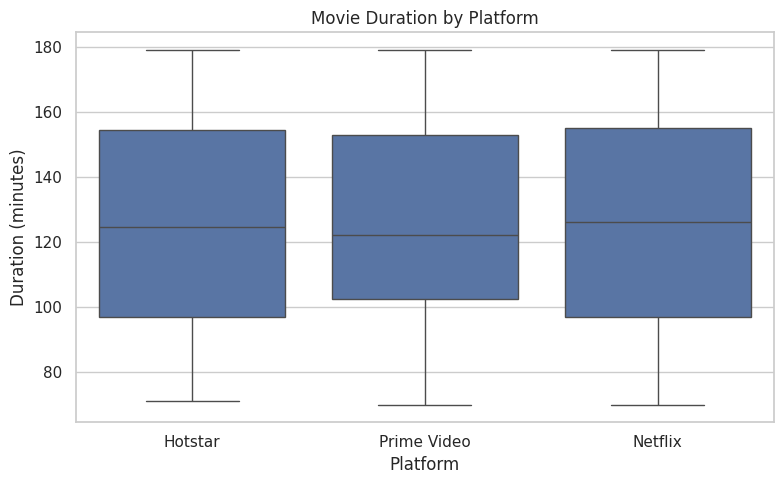

In [25]:
# Chart 6: Movie duration by platform
movies = df[df["type"] == "Movie"].dropna(subset=["duration_minutes"])
plt.figure(figsize=(8,5))
sns.boxplot(data=movies, x="platform", y="duration_minutes")
plt.title("Movie Duration by Platform"); plt.xlabel("Platform"); plt.ylabel("Duration (minutes)")
plt.tight_layout(); plt.show()


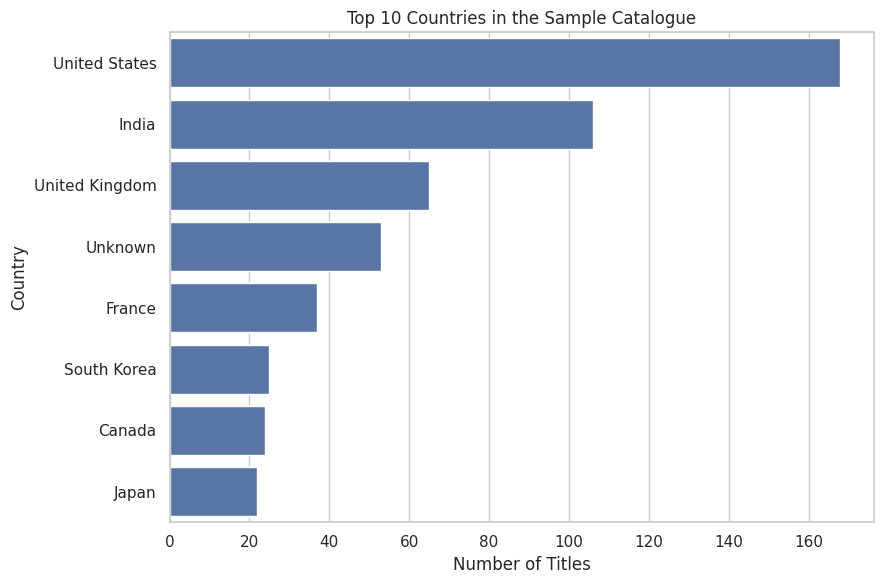

In [26]:
# Chart 7: Top countries represented
top_countries = df["country"].value_counts().head(10).reset_index()
top_countries.columns = ["country","titles"]
plt.figure(figsize=(9,6))
sns.barplot(data=top_countries, y="country", x="titles")
plt.title("Top 10 Countries in the Sample Catalogue"); plt.xlabel("Number of Titles"); plt.ylabel("Country")
plt.tight_layout(); plt.show()


## 4. Summary tables and actionable observations

In [27]:
platform_summary = df.groupby("platform").agg(
    title_count=("show_id","count"),
    movies=("type", lambda x: (x=="Movie").sum()),
    tv_shows=("type", lambda x: (x=="TV Show").sum())
).reset_index()
genre_summary = df["genre"].value_counts().rename_axis("genre").reset_index(name="title_count")
rating_summary = df["rating"].value_counts().rename_axis("rating").reset_index(name="title_count")
display(platform_summary)
display(genre_summary.head(5))
display(rating_summary)


,platform,title_count,movies,tv_shows
0,Hotstar,131,88,43
1,Netflix,207,133,74
2,Prime Video,162,99,63


,genre,title_count
0,Comedy,75
1,Drama,75
2,Thriller,75
3,Documentary,73
4,Romance,73


,rating,title_count
0,G,94
1,TV-MA,89
2,PG,84
3,PG-13,82
4,TV-14,78
5,R,73


## 5. Business interpretation

Use the summary tables and charts to discuss catalogue balance, genre opportunities, content formats and regional representation. Because the data is synthetic, findings demonstrate the analysis method only and must not be presented as actual platform strategy or market facts.

## 6. SQL practice

The accompanying `ott_analysis_queries.sql` contains queries for platform totals, genre popularity, genre mix, format split, release-year trend, average movie duration, country representation and rating distribution.